In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## dapo-fig2

**Figure 2: Accuracy on AIME (avg@32) over training, with and without Clip-Higher.** Dashed lines mark each run's best accuracy. With Clip-Higher, accuracy keeps rising to a best of 0.406, while without it stalls early at a best of 0.269.

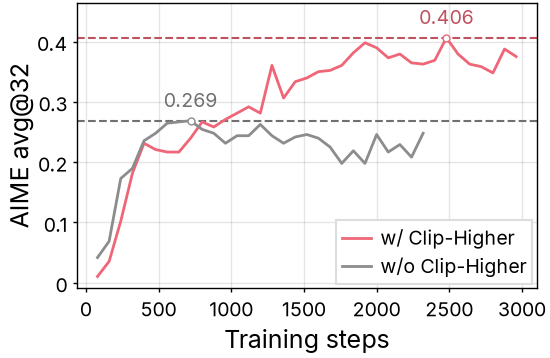

In [2]:
with open("../data/dapo.json") as f:
    data = json.load(f)["fig2a"]

fig, ax = plt.subplots(figsize=(2.75, 2))
ours, base = data["w/ Clip-Higher"], data["w/o Clip-Higher"]
ax.plot(ours["step"], ours["value"], color=colors["ours"], label="w/ Clip-Higher")
ax.plot(base["step"], base["value"], color=colors["neutral"], label="w/o Clip-Higher")

for run, color in [(ours, colors["ours"]), (base, colors["neutral"])]:
    best = int(np.argmax(run["value"]))
    mark_value(ax, run["step"][best], run["value"][best], f"{run['value'][best]:#.3g}", color)

ax.set_xlabel("Training steps")
ax.set_ylabel("AIME avg@32")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}".replace("-", "−"))
ax.legend(loc="lower right")
fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/dapo-fig2.pdf")
fig.savefig("../outputs/dapo-fig2.png")
plt.show()

## dapo-fig6

**Figure 6: Accuracy on AIME (avg@32) over training on a baseline setting, before and after applying dynamic sampling.** Dashed lines mark each run's best accuracy. With dynamic sampling, the run reaches its best of 0.438 at step 2,320, while without it the best is 0.421, reached only at step 6,080, 2.6× more steps.

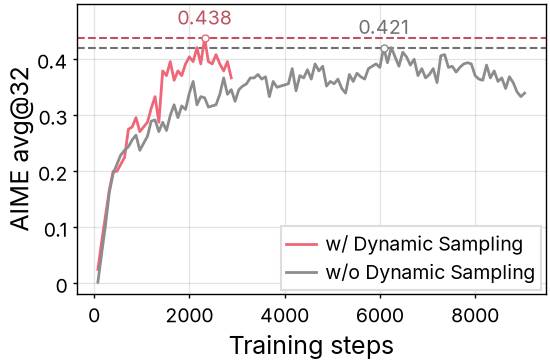

In [3]:
with open("../data/dapo.json") as f:
    data = json.load(f)["fig6"]

fig, ax = plt.subplots(figsize=(2.75, 2))
ours, base = data["w/ Dynamic Sampling"], data["w/o Dynamic Sampling"]
ax.plot(ours["step"], ours["value"], color=colors["ours"], label="w/ Dynamic Sampling")
ax.plot(base["step"], base["value"], color=colors["neutral"], label="w/o Dynamic Sampling")

for run, color in [(ours, colors["ours"]), (base, colors["neutral"])]:
    best = int(np.argmax(run["value"]))
    mark_value(ax, run["step"][best], run["value"][best], f"{run['value'][best]:#.3g}", color)

ax.set_xlabel("Training steps")
ax.set_ylabel("AIME avg@32")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}".replace("-", "−"))
ax.legend(loc="lower right")
fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/dapo-fig6.pdf")
fig.savefig("../outputs/dapo-fig6.png")
plt.show()

## rlvr-fig2

**Figure 2: Pass@k of base models and their RLVR-trained counterparts across mathematical benchmarks.** Rows are models and columns are benchmarks; the x axis is on a log₂ scale. RL-trained models lead at small k (Qwen2.5-7B on AIME24: 0.154 vs. 0.0738 at k = 1), but base models catch up as k grows to the tens or hundreds and end ahead in every panel (0.767 vs. 0.633 at k = 1024).

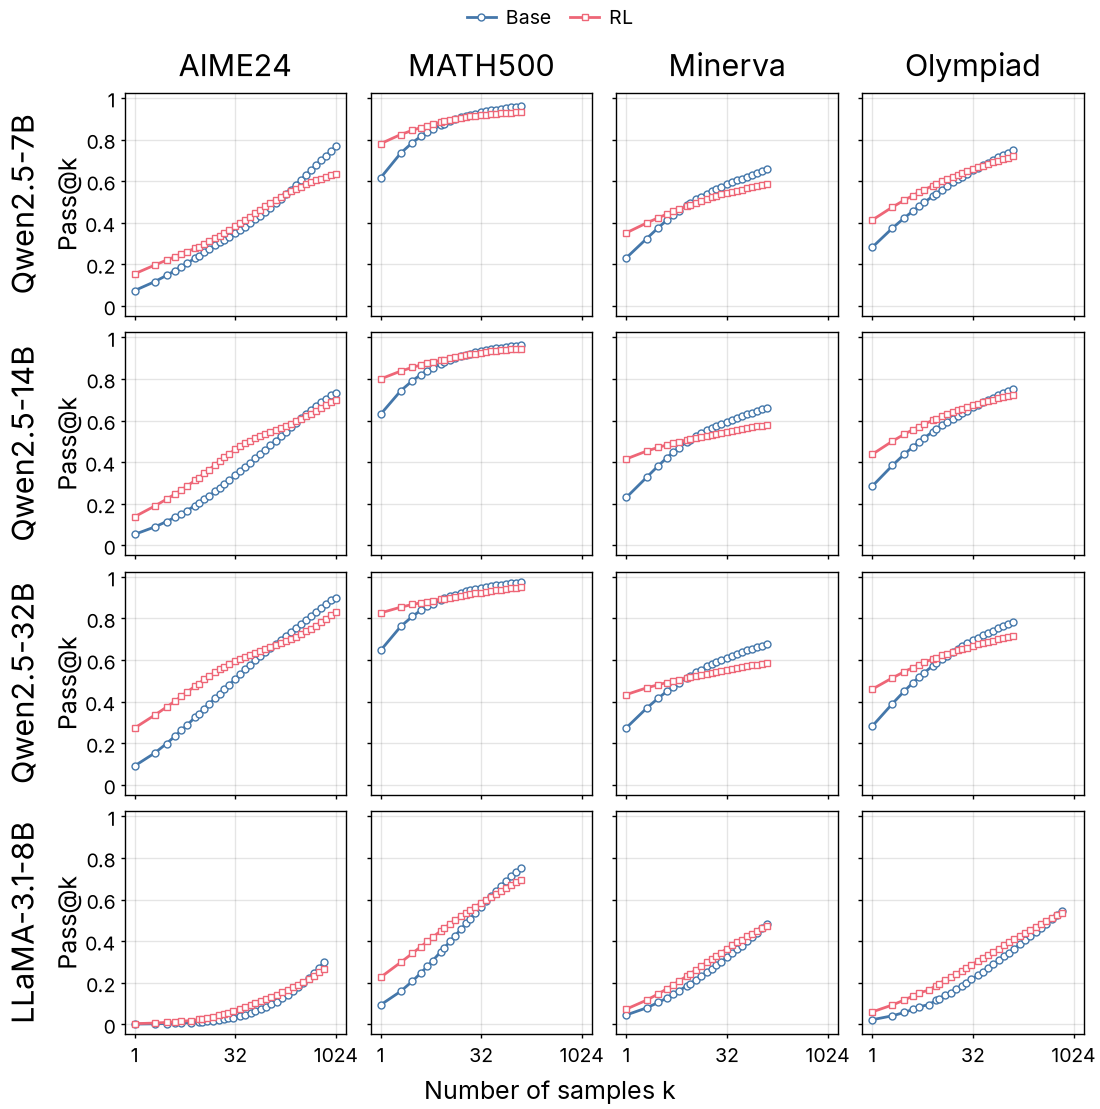

In [4]:
with open("../data/rlvr.json") as f:
    data = json.load(f)

benchmarks = ["AIME24", "MATH500", "Minerva", "Olympiad"]
models = ["Qwen2.5-7B", "Qwen2.5-14B", "Qwen2.5-32B", "LLaMA-3.1-8B"]

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5), sharex=True, sharey=True)
for r, model in enumerate(models):
    for c, benchmark in enumerate(benchmarks):
        ax = axes[r, c]
        for name, marker, color in [("Base", "o", colors["series-1"]), ("RL", "s", colors["series-2"])]:
            curve = data[benchmark][model][name]
            ax.plot(curve["k"], curve["pass"], marker + "-", color=color, label=name)
        ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1])
        ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}".replace("-", "−"))

top = 2 ** math.ceil(math.log2(max(data[b][m]["Base"]["k"][-1] for b in benchmarks for m in models)))
ks = [2 ** e for e in range(0, int(math.log2(top)) + 1, 5)]
axes[0, 0].set_xscale("log", base=2)
axes[0, 0].set_xticks(ks, labels=[str(k) for k in ks])
axes[0, 0].set_xticks([], minor=True)
margin = 2 ** (0.05 * math.log2(top))
axes[0, 0].set_xlim(1 / margin, top * margin)
for c, benchmark in enumerate(benchmarks):
    axes[0, c].set_title(benchmark)

for r, model in enumerate(models):
    axes[r, 0].set_ylabel("Pass@k")
    axes[r, 0].annotate(model, xy=(0, 0.5), xycoords=axes[r, 0].yaxis.label, xytext=(-4, 0),
                        textcoords="offset points", ha="right", va="center", rotation=90, fontsize=11)

fig.supxlabel("Number of samples k")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False, borderaxespad=0)
fit_height(fig, axes, aspect=1.0, min_width=1.0)
fig.savefig("../outputs/rlvr-fig2.pdf")
fig.savefig("../outputs/rlvr-fig2.png")
plt.show()

## rlvr-fig5

**Figure 5: Per-problem accuracy of Qwen2.5-7B on Minerva (272 problems), base model vs. its RLVR-trained version.** Bars count the problems whose accuracy falls in each interval; 0.0 and 1.0 are bins of their own. RLVR raises the number of problems solved every time from 3 to 47 and lowers low accuracies ((0.0, 0.1]: 52 → 33), but also raises the number never solved from 93 to 113.

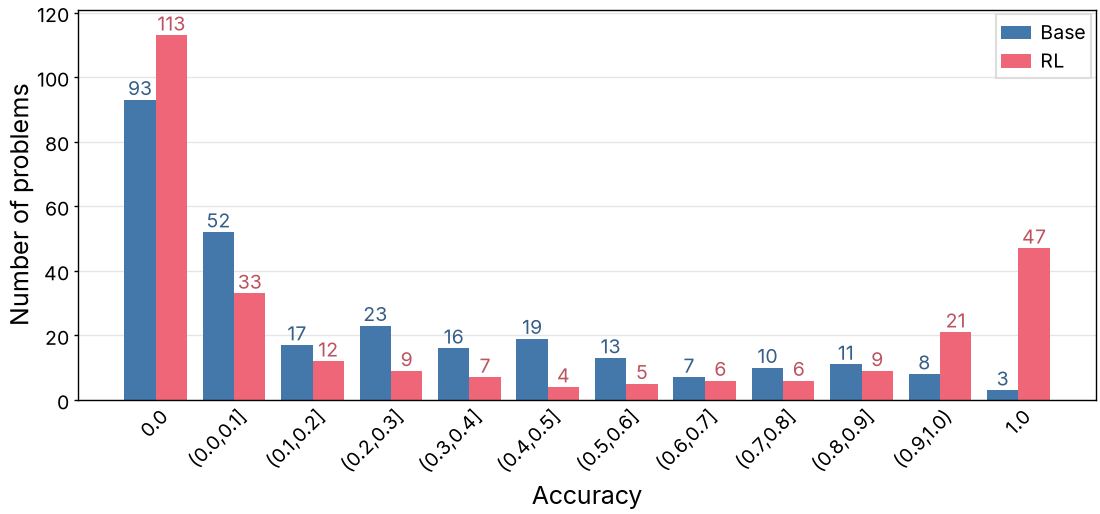

In [5]:
with open("../data/rlvr-fig5.json") as f:
    data = json.load(f)

x = np.arange(len(data["bins"]))
width = 0.8 / 2
fig, ax = plt.subplots(figsize=(5.5, 2))
for i, (name, color) in enumerate([("Base", colors["series-1"]), ("RL", colors["series-2"])]):
    bars = ax.bar(x + (i - 0.5) * width, data[name], width, color=color, linewidth=0, label=name)
    ax.bar_label(bars, fmt="%d", color=darken(color))

ax.set_xticks(x, labels=data["bins"], rotation=45, ha="right", rotation_mode="anchor")
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Accuracy")
ax.set_ylabel("Number of problems")
ax.legend(loc="upper right")
fit_height(fig, ax, aspect=0.382)
fig.savefig("../outputs/rlvr-fig5.pdf")
fig.savefig("../outputs/rlvr-fig5.png")
plt.show()

## rlvr-fig6

**Figure 6: Perplexity of individual responses to an AIME24 problem under the base model (Qwen2.5-7B) and its RLVR-trained version.** PPL_M(Y_S) is model M's perplexity on responses sampled from S (16 per model; 7 from OpenAI-o1 as Y_GT); boxes span the quartiles with the median as a line, whiskers reach 1.5× the interquartile range, and each point is one response. The base model's perplexity on RL responses (median 1.056) falls in the lower part of its perplexity on its own responses (median 1.084), so the RL model generates responses the base model already tends to produce.

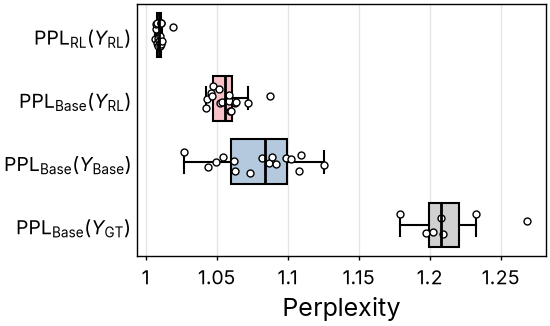

In [6]:
with open("../data/rlvr-fig6.json") as f:
    data = json.load(f)["Problem 1"]

groups = [
    ("PPL_RL(Y_RL)", r"$\mathrm{PPL}_{\mathrm{RL}}(Y_{\mathrm{RL}})$", lighten(colors["neutral"])),
    ("PPL_Base(Y_RL)", r"$\mathrm{PPL}_{\mathrm{Base}}(Y_{\mathrm{RL}})$", lighten(colors["series-2"])),
    ("PPL_Base(Y_Base)", r"$\mathrm{PPL}_{\mathrm{Base}}(Y_{\mathrm{Base}})$", lighten(colors["series-1"])),
    ("PPL_Base(Y_GT)", r"$\mathrm{PPL}_{\mathrm{Base}}(Y_{\mathrm{GT}})$", lighten(colors["neutral"])),
]

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(2.75, 2))
for y, (key, label, fill) in enumerate(groups):
    values = data[key]
    box = ax.boxplot(values, positions=[y], widths=0.7, orientation="horizontal", showfliers=False)
    box["boxes"][0].set_facecolor(fill)
    ax.plot(values, y + rng.uniform(-0.2, 0.2, len(values)), "o", color="black", markerfacecolor="white", linestyle="none")

ax.set_yticks(range(len(groups)), labels=[label for _, label, _ in groups])
ax.invert_yaxis()
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Perplexity")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:g}".replace("-", "−"))
fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/rlvr-fig6.pdf")
fig.savefig("../outputs/rlvr-fig6.png")
plt.show()